# Final evaluation and diagnostics

Freeze the winner from earlier-fold scores before evaluating July 2024–March 2025. This block was previously examined in Notebook 05 and is not fully untouched. Diagnose subgroup bias and a 16-month backtest; generate a separate improved submission without replacing baseline files.

Run notebooks 06–10 in order. Existing notebooks 01–05 and processed datasets are read-only inputs. Results are written to `experiments/results/`. Scores use individual rents in SGD; tuning folds are July–December 2023 and January–June 2024. No final-block scores are used in model or feature selection.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd() if (Path.cwd() / "data/train.csv").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from experiments import rental_experiments as exp


In [2]:
scores = exp.final_evaluation()
display(scores)
import json
display(json.loads((exp.OUT / "final_selection.json").read_text()))
display(json.loads((exp.OUT / "final_refit.json").read_text()))

Final block: {'model': 'ridge', 'evaluation': 'final_block', 'RMSE': 582.2640715696456, 'MAE': 432.27380189209805, 'bias_actual_minus_predicted': -337.79337933705494, 'train_rows': 124016, 'evaluation_rows': 25984, 'seconds': 2.0920248340044054}


Final block: {'model': 'catboost', 'evaluation': 'final_block', 'RMSE': 458.7397674055674, 'MAE': 334.4122704884221, 'bias_actual_minus_predicted': 13.551486060575492, 'selected_iterations': 468, 'train_rows': 124016, 'evaluation_rows': 25984, 'seconds': 64.0001464579982}


Final block: {'model': 'mlp', 'evaluation': 'final_block', 'RMSE': 469.7292124754341, 'MAE': 347.43953851878524, 'bias_actual_minus_predicted': 34.85328155973082, 'selected_iterations': 5, 'internal_rmse_curve': [549.246687381895, 540.1961358434688, 531.1254683679199, 524.948438474054, 520.5587317758399, 521.792506655198, 526.0336170217519, 528.5491989230676, 535.3904715962343, 539.9215958942267, 548.6140662344567], 'train_rows': 124016, 'evaluation_rows': 25984, 'seconds': 21.17437904200051}


,model,evaluation,RMSE,MAE,bias_actual_minus_predicted,train_rows,evaluation_rows,seconds,selected_iterations,internal_rmse_curve
0,ridge,final_block,582.264072,432.273802,-337.793379,124016,25984,2.092025,NaN,NaN
1,catboost,final_block,458.739767,334.412270,13.551486,124016,25984,64.000146,468.0,NaN
2,mlp,final_block,469.729212,347.439539,34.853282,124016,25984,21.174379,5.0,"[549.246687381895, 540.1961358434688, 531.1254..."
3,ridge,16_month_backtest,624.419103,473.995460,-263.517361,87937,47528,1.565479,NaN,NaN
4,catboost,16_month_backtest,534.106274,410.922845,30.370780,87937,47528,25.732344,271.0,NaN


{'model': 'catboost',
 'params': {'depth': 8, 'l2_leaf_reg': 3, 'learning_rate': 0.05},
 'group': 'base',
 'policy': 'keep_all',
 'imputation': 'block_recovery',
 'mean_RMSE': 547.3718358942915,
 'feature_selection_rule': 'Minimum earlier-fold mean RMSE; retain base if improvement <1 SGD.',
 'seed_policy': 'MLP uses predeclared seed 42; other seeds are stability diagnostics.',
 'selection_basis': 'earlier folds only; final block is diagnostic, not used to switch winners'}

{'submission': 'submissions/catboost_improved.csv',
 'selected_iterations': 499,
 'train_rows': 150000,
 'evaluation_rows': 50000,
 'seconds': 81.39161266700103,
 'model_features': ['TOWN',
  'BLOCK',
  'STREET',
  'FLAT_TYPE',
  'FLAT_MODEL',
  'FLOOR_AREA_SQM',
  'LEASE_COMMENCE_DATE',
  'RENT_YEAR',
  'RENT_MONTH',
  'RENT_QUARTER',
  'MONTH_INDEX',
  'MONTH_SIN',
  'MONTH_COS',
  'PROPERTY_KEY',
  'TOWN_STREET',
  'FLAT_TYPE_ORDER',
  'LEASE_AGE_INVALID',
  'LEASE_AGE_AT_RENT',
  'LOG_FLOOR_AREA_SQM',
  'HDB_LATITUDE',
  'HDB_LONGITUDE',
  'HDB_MAX_FLOOR',
  'HDB_YEAR_COMPLETED',
  'HDB_MAX_FLOOR_INVALID',
  'HDB_YEAR_COMPLETED_INVALID',
  'HDB_POSTAL_SECTOR',
  'HDB_SUBZONE',
  'HDB_PLANNING_AREA',
  'HDB_REGION',
  'DIST_TO_NEAREST_PRE2021_MRT_KM',
  'PRE2021_MRT_COUNT_WITHIN_500M',
  'PRE2021_MRT_COUNT_WITHIN_1KM',
  'HDB_MATCHED',
  'HDB_BUILDING_AGE_INVALID',
  'HDB_BUILDING_AGE_AT_RENT'],
 'target': 'MONTHLY_RENT',
 'categorical_features': ['TOWN',
  'BLOCK',
  'STREET',
  'F

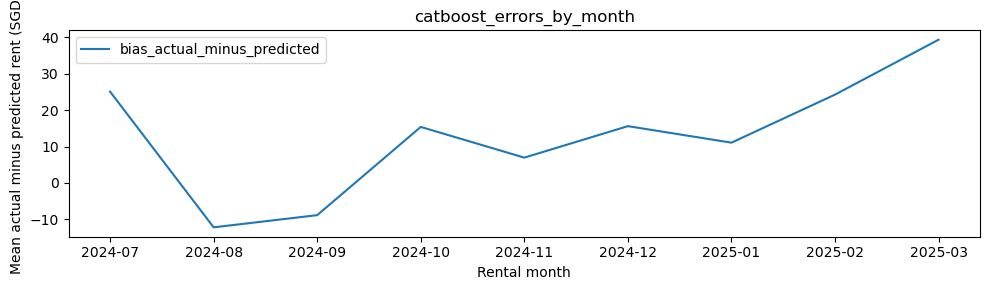

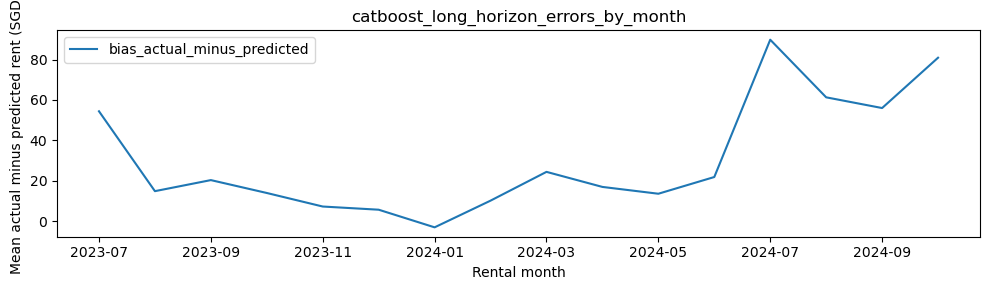

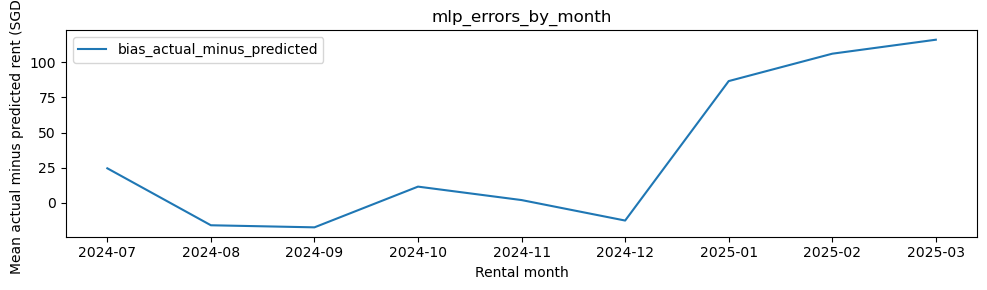

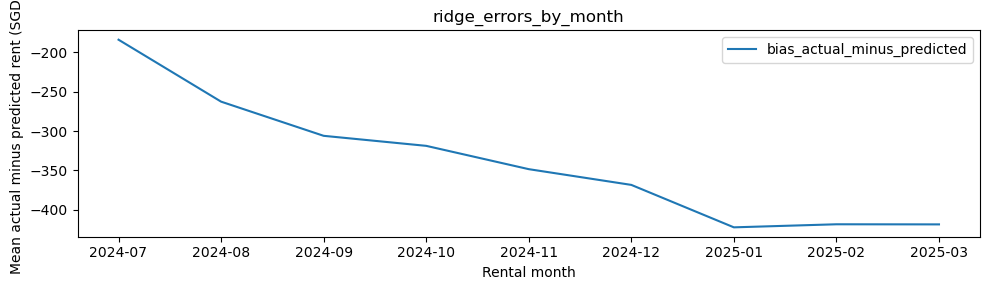

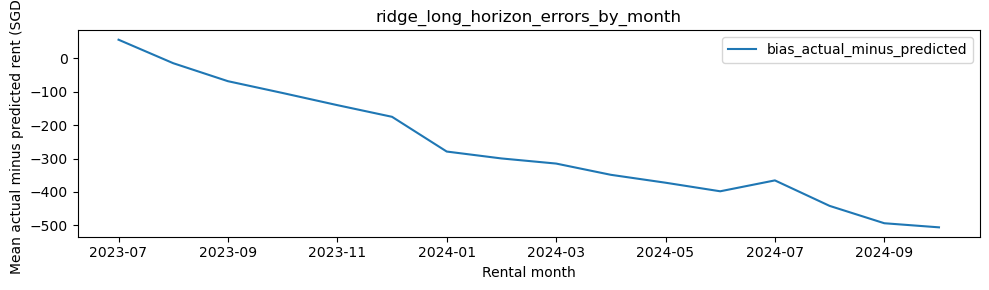

In [3]:
for path in sorted(exp.OUT.glob("*_errors_by_month.csv")):
    frame = pd.read_csv(path)
    frame.plot(x="month", y="bias_actual_minus_predicted", title=path.stem, figsize=(10, 3))
    plt.ylabel("Mean actual minus predicted rent (SGD)")
    plt.xlabel("Rental month")
    plt.tight_layout()
    plt.show()

In [4]:
for path in sorted(exp.OUT.glob("*_errors_by_FLAT_TYPE.csv")):
    print(path.name)
    display(pd.read_csv(path))

catboost_errors_by_FLAT_TYPE.csv


,FLAT_TYPE,rows,MAE,bias_actual_minus_predicted,RMSE
0,1-room,10,347.279676,163.618101,383.267982
1,2-room,708,313.641648,41.790895,437.930187
2,3-room,8562,322.921425,16.766107,432.546726
3,4-room,9468,336.209441,8.207177,462.563588
4,5-room,5927,334.601459,7.832742,469.356608
5,executive,1309,406.852775,40.653981,551.020357


catboost_long_horizon_errors_by_FLAT_TYPE.csv


,FLAT_TYPE,rows,MAE,bias_actual_minus_predicted,RMSE
0,1-room,13,385.991850,-77.644249,440.381481
1,2-room,1219,349.252859,-114.318215,501.145069
2,3-room,15570,390.400833,33.370311,494.638408
3,4-room,17310,416.598384,11.914329,541.359385
4,5-room,10964,419.159202,65.951600,553.057166
5,executive,2452,495.131871,55.024297,642.921247


mlp_errors_by_FLAT_TYPE.csv


,FLAT_TYPE,rows,MAE,bias_actual_minus_predicted,RMSE
0,1-room,10,296.533202,69.559115,339.232607
1,2-room,708,305.772324,-6.291411,434.577805
2,3-room,8562,325.613901,8.399483,437.023911
3,4-room,9468,353.066366,51.110072,474.409247
4,5-room,5927,356.277008,43.463838,484.680985
5,executive,1309,432.409797,73.299993,579.694303


ridge_errors_by_FLAT_TYPE.csv


,FLAT_TYPE,rows,MAE,bias_actual_minus_predicted,RMSE
0,1-room,10,497.500550,-497.500550,588.247833
1,2-room,708,492.859890,-471.226381,642.253725
2,3-room,8562,465.554063,-424.065922,608.682374
3,4-room,9468,417.026550,-320.437741,570.262965
4,5-room,5927,403.062157,-264.253548,552.324704
5,executive,1309,423.874709,-158.618906,589.324634


ridge_long_horizon_errors_by_FLAT_TYPE.csv


,FLAT_TYPE,rows,MAE,bias_actual_minus_predicted,RMSE
0,1-room,13,743.730360,-735.866543,872.703210
1,2-room,1219,529.671581,-452.297553,689.066222
2,3-room,15570,502.010568,-385.569135,647.197992
3,4-room,17310,462.569568,-234.073559,612.455697
4,5-room,10964,440.848696,-156.107786,593.360830
5,executive,2452,495.868362,-80.279635,659.821249


## Interpretation

Read per-fold scores before interpreting the mean. A lower score does not establish causality. Explain temporal drift, duplicate uncertainty, snapshot limitations, and computational cost in the report. Hyperparameters and selections are saved alongside results.

References: [CatBoost fit API](https://catboost.ai/docs/en/concepts/python-reference_catboostregressor_fit); [scikit-learn MLPRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPRegressor.html).